# Data Validation

## Introduction

Data validation is the process of checking whether data is correct, complete, consistent, and follows the required rules.

It helps us identify incorrect, missing, duplicate, or unexpected values before using a dataset for analysis or machine learning.

For example:
- Age should not be negative.
- Marks should be between 0 and 100.
- Email addresses should follow a valid format.
- Student IDs should be unique.
- Department values should belong to approved categories.

In this notebook, we will learn how to validate data using Python and Pandas.

## Objectives

- Understand data validation.
- Validate data types and ranges.
- Check formats and categories.
- Identify null values.
- Apply business rules.
- Validate dates.
- Check unique IDs and constraints.
- Identify invalid records.
- Generate a final data validation report.

## 1. What is Data Validation?

Data validation means checking whether the values in a dataset follow predefined rules and requirements.

It ensures that data is suitable for analysis and machine learning.

### Why is data validation important?

- Improves data quality.
- Identifies incorrect values.
- Detects missing information.
- Prevents invalid records from entering the dataset.
- Helps maintain consistency.
- Improves the reliability of machine learning models.

### Examples

| Column | Validation Rule |
|---|---|
| Age | Should be between 16 and 100 |
| Marks | Should be between 0 and 100 |
| Email | Should follow a valid email format |
| Department | Should contain approved department names |
| Student_ID | Should be unique |
| Joining_Date | Should contain valid dates |

In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Creating a Sample Dataset

We will create a student dataset containing both valid and invalid values.

The dataset includes:
- Student ID
- Student name
- Age
- Email
- Department
- Marks
- Attendance
- Joining date
- Course ID

We will use this dataset to practice different data validation techniques.

In [2]:
data = {
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 101],
    "Name": ["Asha", "Rahul", "Priya", "Kiran", "Sneha", None, "Meena", "Asha"],
    "Age": [20, -5, 150, 22, None, 21, 23, 20],
    "Email": [
        "asha@gmail.com",
        "rahul@gmail",
        "priya@gmail.com",
        "kiran123",
        "sneha@yahoo.com",
        "arun@gmail.com",
        "meena@gmail.com",
        "asha@gmail.com"
    ],
    "Department": ["AI", "CS", "AI", "EC", "IT", "CS", "XYZ", "AI"],
    "Marks": [85, 110, -10, 75, None, 88, 92, 85],
    "Attendance": [90, 105, 80, 75, 88, -5, 95, 90],
    "Joining_Date": [
        "01-06-2026",
        "15-06-2026",
        "35-15-2026",
        "20-06-2026",
        "25-06-2026",
        "30-06-2026",
        "10-07-2026",
        "01-06-2026"
    ],
    "Course_ID": ["C01", "C02", "C01", "C03", "C04", "C02", "C99", "C01"]
}

df = pd.DataFrame(data)

display(df)

,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,10-07-2026,C99
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01


## 3. Understanding the Dataset

Before validating the dataset, we should inspect its structure.

We will use:
- head() to display the first five records.
- shape to check the number of rows and columns.
- info() to check column names and data types.
- describe() to understand numerical values.

In [3]:
print("First five records:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

First five records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04


Dataset shape: (8, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Student_ID    8 non-null      int64  
 1   Name          7 non-null      str    
 2   Age           7 non-null      float64
 3   Email         8 non-null      str    
 4   Department    8 non-null      str    
 5   Marks         7 non-null      float64
 6   Attendance    8 non-null      int64  
 7   Joining_Date  8 non-null      str    
 8   Course_ID     8 non-null      str    
dtypes: float64(2), int64(2), str(5)
memory usage: 969.0 bytes

Numerical summary:


,Student_ID,Age,Marks,Attendance
count,8.000000,7.000000,7.000000,8.000000
mean,103.625000,35.857143,75.000000,77.250000
std,2.263846,51.281668,38.961519,34.441462
min,101.000000,-5.000000,-10.000000,-5.000000
25%,101.750000,20.000000,80.000000,78.750000
50%,103.500000,21.000000,85.000000,89.000000
75%,105.250000,22.500000,90.000000,91.250000
max,107.000000,150.000000,110.000000,105.000000


## 4. Data Type Validation

Data type validation checks whether each column contains the expected type of data.

Examples:
- Student_ID should contain integer values.
- Age should contain numerical values.
- Marks should contain numerical values.
- Joining_Date should contain date values.
- Name and Email should contain text.

Incorrect data types can cause problems during analysis and machine learning.

In [4]:
print("Column data types:")
print(df.dtypes)

# Check whether important columns have expected data types
print("\nStudent_ID is numeric:", pd.api.types.is_numeric_dtype(df["Student_ID"]))
print("Age is numeric:", pd.api.types.is_numeric_dtype(df["Age"]))
print("Marks is numeric:", pd.api.types.is_numeric_dtype(df["Marks"]))
print("Name is text:", pd.api.types.is_string_dtype(df["Name"]))

Column data types:
Student_ID        int64
Name                str
Age             float64
Email               str
Department          str
Marks           float64
Attendance        int64
Joining_Date        str
Course_ID           str
dtype: object

Student_ID is numeric: True
Age is numeric: True
Marks is numeric: True
Name is text: True


## 5. Range Validation

Range validation checks whether numerical values fall within an acceptable minimum and maximum range.

Examples:
- Age should be between 16 and 100.
- Marks should be between 0 and 100.
- Attendance should be between 0 and 100.

Values outside the allowed range are considered invalid.

We will identify these invalid values using comparison operators.

In [5]:
# Age validation
valid_age = df["Age"].between(16, 100)

# Marks validation
valid_marks = df["Marks"].between(0, 100)

# Attendance validation
valid_attendance = df["Attendance"].between(0, 100)

print("Invalid Age records:")
display(df[~valid_age])

print("Invalid Marks records:")
display(df[~valid_marks])

print("Invalid Attendance records:")
display(df[~valid_attendance])

Invalid Age records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04


Invalid Marks records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04


Invalid Attendance records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02


## 6. Format Validation

Format validation checks whether values follow a predefined pattern.

For example, an email address should contain:
- A username.
- The @ symbol.
- A domain name.
- A valid-looking domain extension.

We can use regular expressions (regex) to check formats.

Note: A regex check identifies common formatting problems. It does not prove that an email address actually exists.

In [6]:
email_pattern = r"^[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}$"

valid_email = df["Email"].str.match(email_pattern, na=False)

print("Valid email records:")
display(df[valid_email])

print("Invalid email records:")
display(df[~valid_email])

Valid email records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,10-07-2026,C99
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01


Invalid email records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03


## 7. Category Validation

Category validation checks whether categorical values belong to an approved list.

For example, the allowed departments in our dataset are:
- AI
- CS
- EC
- IT

If a department contains a value such as "XYZ", it is considered invalid.

This validation helps maintain consistency in categorical data.

In [7]:
allowed_departments = ["AI", "CS", "EC", "IT"]

valid_department = df["Department"].isin(allowed_departments)

print("Valid department records:")
display(df[valid_department])

print("Invalid department records:")
display(df[~valid_department])

Valid department records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01


Invalid department records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,10-07-2026,C99


## 8. Null-Value Validation

Null-value validation checks whether required fields contain missing values.

Some columns may be mandatory.

For example:
- Student_ID should not be missing.
- Name should not be missing.
- Marks may be required for student performance analysis.

We can use isnull() to identify missing values.

In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

required_columns = ["Student_ID", "Name", "Marks"]

print("\nMissing values in required columns:")
print(df[required_columns].isnull().sum())

print("\nRecords with missing required values:")
display(df[df[required_columns].isnull().any(axis=1)])

Missing values in each column:
Student_ID      0
Name            1
Age             1
Email           0
Department      0
Marks           1
Attendance      0
Joining_Date    0
Course_ID       0
dtype: int64

Missing values in required columns:
Student_ID    0
Name          1
Marks         1
dtype: int64

Records with missing required values:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02


## 9. Business Rule Validation

Business rule validation checks whether data follows specific rules defined by an organization or business.

Examples:
- A student must be at least 16 years old.
- Marks cannot be greater than 100.
- Attendance cannot be greater than 100.
- A student record must have a valid Student_ID.
- Required student information should not be empty.

Business rules depend on the requirements of the project.

In [9]:
# Business rule 1: Age must be at least 16
rule_age = df["Age"] >= 16

# Business rule 2: Marks must be between 0 and 100
rule_marks = df["Marks"].between(0, 100)

# Business rule 3: Attendance must be between 0 and 100
rule_attendance = df["Attendance"].between(0, 100)

# Combine business rules
business_rules = rule_age & rule_marks & rule_attendance

print("Records following all business rules:")
display(df[business_rules.fillna(False)])

print("Records violating business rules:")
display(df[~business_rules.fillna(False)])

Records following all business rules:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,10-07-2026,C99
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01


Records violating business rules:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02


## 10. Date Validation

Date validation checks whether date values are valid and follow the expected format.

For example:
- 01-06-2026 is a valid date.
- 35-15-2026 is an invalid date.

We can use pd.to_datetime() to convert date values into datetime format.

The errors="coerce" parameter converts invalid dates into NaT (Not a Time).

In [10]:
date_df = df.copy()

date_df["Joining_Date"] = pd.to_datetime(
    date_df["Joining_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Joining dates after conversion:")
display(date_df[["Student_ID", "Joining_Date"]])

print("\nInvalid dates:")
display(date_df[date_df["Joining_Date"].isnull()])

Joining dates after conversion:


,Student_ID,Joining_Date
0,101,2026-06-01
1,102,2026-06-15
2,103,NaT
3,104,2026-06-20
4,105,2026-06-25
5,106,2026-06-30
6,107,2026-07-10
7,101,2026-06-01



Invalid dates:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,NaT,C01


### Observation

The invalid date value is converted into NaT.

NaT indicates that the date could not be converted into a valid datetime value.

We should investigate invalid dates before deciding whether to correct or remove them.

## 11. Unique ID Validation

Unique ID validation checks whether an identifier is repeated in the dataset.

For example, every student should have a unique Student_ID.

If the same Student_ID appears more than once, it may indicate duplicate records or an incorrect data entry.

We can use duplicated() to identify repeated IDs.

In [11]:
duplicate_ids = df["Student_ID"].duplicated(keep=False)

print("Records with repeated Student_ID:")
display(df[duplicate_ids])

print("\nNumber of repeated Student_ID records:")
print(duplicate_ids.sum())

print("\nNumber of unique Student IDs:")
print(df["Student_ID"].nunique())

Records with repeated Student_ID:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01



Number of repeated Student_ID records:
2

Number of unique Student IDs:
7


## 12. Referential Integrity Validation

Referential integrity checks whether values in one dataset correctly refer to existing records in another dataset.

For example:
- A student has a Course_ID.
- That Course_ID should exist in the course master dataset.

If a student has Course_ID "C99", but C99 is not available in the course master dataset, the record violates referential integrity.

This validation is important when working with related tables in databases.

In [12]:
# Course master dataset
courses = pd.DataFrame({
    "Course_ID": ["C01", "C02", "C03", "C04"],
    "Course_Name": [
        "Artificial Intelligence",
        "Computer Science",
        "Electronics",
        "Information Technology"
    ]
})

valid_course_ids = courses["Course_ID"].tolist()

valid_course = df["Course_ID"].isin(valid_course_ids)

print("Valid course records:")
display(df[valid_course])

print("Invalid course records:")
display(df[~valid_course])

Valid course records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,15-06-2026,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,35-15-2026,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,20-06-2026,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01


Invalid course records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,10-07-2026,C99


## 13. Constraint Validation

Constraint validation checks whether data follows specific conditions or restrictions.

Common constraints include:

1. NOT NULL – Required fields cannot be empty.
2. UNIQUE – Values must not be repeated.
3. CHECK – Values must satisfy a condition.
4. PRIMARY KEY – A column or combination of columns uniquely identifies a record.
5. FOREIGN KEY – A value must refer to an existing record in another table.

Examples:
- Student_ID must be unique.
- Name must not be null.
- Marks must be between 0 and 100.
- Course_ID must exist in the course master table.

In [13]:
# NOT NULL constraint
not_null_check = df["Name"].notnull()

# UNIQUE constraint
unique_check = ~df["Student_ID"].duplicated(keep=False)

# CHECK constraint
marks_check = df["Marks"].between(0, 100)

# FOREIGN KEY constraint
foreign_key_check = df["Course_ID"].isin(valid_course_ids)

print("Name NOT NULL check:")
print(not_null_check)

print("\nStudent_ID UNIQUE check:")
print(unique_check)

print("\nMarks CHECK constraint:")
print(marks_check)

print("\nCourse_ID FOREIGN KEY check:")
print(foreign_key_check)

Name NOT NULL check:
0     True
1     True
2     True
3     True
4     True
5    False
6     True
7     True
Name: Name, dtype: bool

Student_ID UNIQUE check:
0    False
1     True
2     True
3     True
4     True
5     True
6     True
7    False
Name: Student_ID, dtype: bool

Marks CHECK constraint:
0     True
1    False
2    False
3     True
4    False
5     True
6     True
7     True
Name: Marks, dtype: bool

Course_ID FOREIGN KEY check:
0     True
1     True
2     True
3     True
4     True
5     True
6    False
7     True
Name: Course_ID, dtype: bool


## 14. Creating a Data Validation Function

Instead of checking every column separately, we can create a function to perform multiple validation checks.

Our function will check:

- Age range.
- Marks range.
- Attendance range.
- Email format.
- Department category.
- Required fields.
- Valid joining date.
- Unique Student_ID.
- Valid Course_ID.

Each record will be checked against these rules.

In [14]:
validation_df = df.copy()

# Convert joining date for validation
validation_df["Joining_Date"] = pd.to_datetime(
    validation_df["Joining_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

def validate_student_data(data):
    results = pd.DataFrame(index=data.index)

    results["Age_Valid"] = data["Age"].between(16, 100)
    results["Marks_Valid"] = data["Marks"].between(0, 100)
    results["Attendance_Valid"] = data["Attendance"].between(0, 100)

    results["Email_Valid"] = data["Email"].str.match(
        email_pattern, na=False
    )

    results["Department_Valid"] = data["Department"].isin(
        allowed_departments
    )

    results["Required_Fields_Valid"] = data[
        ["Student_ID", "Name", "Marks"]
    ].notnull().all(axis=1)

    results["Date_Valid"] = data["Joining_Date"].notnull()

    results["Student_ID_Unique"] = ~data[
        "Student_ID"
    ].duplicated(keep=False)

    results["Course_ID_Valid"] = data["Course_ID"].isin(
        valid_course_ids
    )

    results["Overall_Valid"] = results.all(axis=1)

    return results

validation_results = validate_student_data(validation_df)

display(validation_results)

,Age_Valid,Marks_Valid,Attendance_Valid,Email_Valid,Department_Valid,Required_Fields_Valid,Date_Valid,Student_ID_Unique,Course_ID_Valid,Overall_Valid
0,True,True,True,True,True,True,True,False,True,False
1,False,False,False,False,True,True,True,True,True,False
2,False,False,True,True,True,True,False,True,True,False
3,True,True,True,False,True,True,True,True,True,False
4,False,False,True,True,True,False,True,True,True,False
5,True,True,False,True,True,False,True,True,True,False
6,True,True,True,True,False,True,True,True,False,False
7,True,True,True,True,True,True,True,False,True,False


## 15. Identifying Valid and Invalid Records

After applying validation rules, we can separate valid and invalid records.

- Valid records follow all the defined validation rules.
- Invalid records violate one or more validation rules.

We should investigate invalid records before correcting or removing them.

In [15]:
valid_records = validation_df[
    validation_results["Overall_Valid"]
]

invalid_records = validation_df[
    ~validation_results["Overall_Valid"]
]

print("Valid records:")
display(valid_records)

print("Invalid records:")
display(invalid_records)

print("Total valid records:", len(valid_records))
print("Total invalid records:", len(invalid_records))

Valid records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID


Invalid records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,2026-06-01,C01
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,2026-06-15,C02
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,NaT,C01
3,104,Kiran,22.0,kiran123,EC,75.0,75,2026-06-20,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,2026-06-25,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,2026-06-30,C02
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,2026-07-10,C99
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,2026-06-01,C01


Total valid records: 0
Total invalid records: 8


## 16. Finding Reasons for Validation Failure

It is important to understand why a record failed validation.

We can combine the validation results with the original records to identify which rules were violated.

This helps us investigate and correct data quality problems.

In [16]:
invalid_details = validation_df.join(validation_results)

invalid_details = invalid_details[
    ~invalid_details["Overall_Valid"]
]

display(invalid_details)

,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID,Age_Valid,Marks_Valid,Attendance_Valid,Email_Valid,Department_Valid,Required_Fields_Valid,Date_Valid,Student_ID_Unique,Course_ID_Valid,Overall_Valid
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,2026-06-01,C01,True,True,True,True,True,True,True,False,True,False
1,102,Rahul,-5.0,rahul@gmail,CS,110.0,105,2026-06-15,C02,False,False,False,False,True,True,True,True,True,False
2,103,Priya,150.0,priya@gmail.com,AI,-10.0,80,NaT,C01,False,False,True,True,True,True,False,True,True,False
3,104,Kiran,22.0,kiran123,EC,75.0,75,2026-06-20,C03,True,True,True,False,True,True,True,True,True,False
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,2026-06-25,C04,False,False,True,True,True,False,True,True,True,False
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,2026-06-30,C02,True,True,False,True,True,False,True,True,True,False
6,107,Meena,23.0,meena@gmail.com,XYZ,92.0,95,2026-07-10,C99,True,True,True,True,False,True,True,True,False,False
7,101,Asha,20.0,asha@gmail.com,AI,85.0,90,2026-06-01,C01,True,True,True,True,True,True,True,False,True,False


## 17. Data Validation Summary Report

A validation summary report shows how many records passed or failed each validation rule.

This helps us understand the overall quality of the dataset.

In [17]:
validation_columns = validation_results.drop(
    columns=["Overall_Valid"]
)

validation_summary = pd.DataFrame({
    "Valid_Records": validation_columns.sum(),
    "Invalid_Records": (~validation_columns).sum()
})

validation_summary["Invalid_Percentage"] = (
    validation_summary["Invalid_Records"] /
    len(validation_results)
) * 100

display(validation_summary)

,Valid_Records,Invalid_Records,Invalid_Percentage
Age_Valid,5,3,37.5
Marks_Valid,5,3,37.5
Attendance_Valid,6,2,25.0
Email_Valid,6,2,25.0
Department_Valid,7,1,12.5
Required_Fields_Valid,6,2,25.0
Date_Valid,7,1,12.5
Student_ID_Unique,6,2,25.0
Course_ID_Valid,7,1,12.5


## 18. Visualizing Validation Results

A bar chart helps us compare the number of valid and invalid records for each validation rule.

It provides a quick understanding of which rules have the most failures.

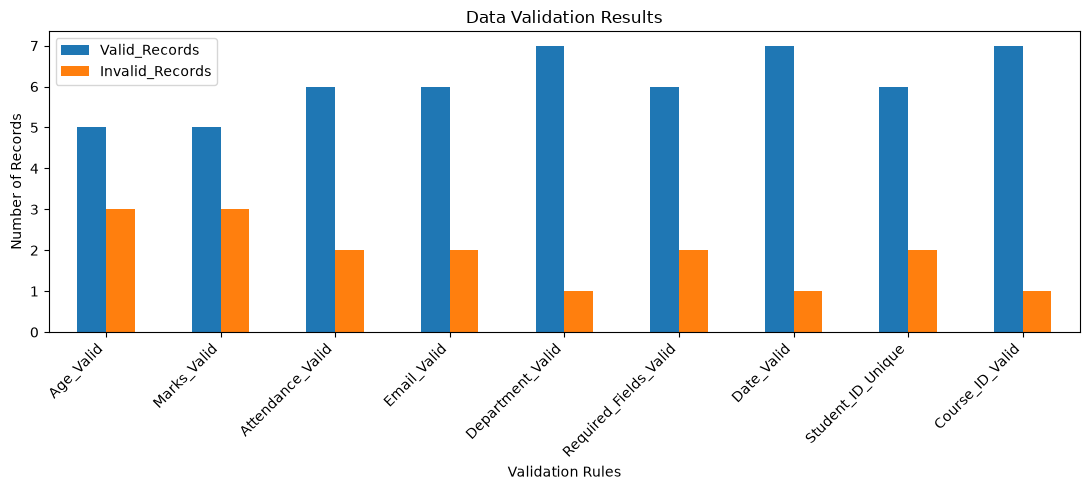

In [18]:
validation_summary[
    ["Valid_Records", "Invalid_Records"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

import matplotlib.pyplot as plt

plt.title("Data Validation Results")
plt.xlabel("Validation Rules")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 19. Correcting Invalid Data

After identifying invalid records, we should investigate the reason for each issue.

Some values can be corrected when the correct information is available.

Examples:
- Correct an incorrect email using the original source.
- Correct an invalid date using verified information.
- Replace an incorrect department with the approved category.
- Investigate repeated Student_ID values before deciding which record to retain.

Important: We should not guess missing or incorrect values. If the correct information is unavailable, we should flag the record for review or keep it separate.

## 20. Applying Verified Corrections

For practice, we will create a small corrected dataset using known corrections.

These corrections are only examples to demonstrate the process. In a real project, corrections must come from a trusted source.

We will:
- Correct the invalid age using verified information.
- Correct the invalid email format.
- Correct the invalid department category.
- Correct the invalid date.
- Remove a duplicate record only after deciding which record should be retained.

In [19]:
corrected_df = df.copy()

# Example corrections based on assumed verified source information
corrected_df.loc[corrected_df["Student_ID"] == 102, "Age"] = 25

corrected_df.loc[corrected_df["Student_ID"] == 103, "Age"] = 22

corrected_df.loc[corrected_df["Student_ID"] == 102, "Email"] = "rahul@gmail.com"

corrected_df.loc[corrected_df["Student_ID"] == 104, "Email"] = "kiran@gmail.com"

corrected_df.loc[corrected_df["Student_ID"] == 107, "Department"] = "AI"

corrected_df.loc[corrected_df["Student_ID"] == 103, "Joining_Date"] = "25-06-2026"

# Remove the repeated Student_ID record after review
corrected_df = corrected_df.drop_duplicates(
    subset=["Student_ID"],
    keep="first"
)

display(corrected_df)

,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
0,101,Asha,20.0,asha@gmail.com,AI,85.0,90,01-06-2026,C01
1,102,Rahul,25.0,rahul@gmail.com,CS,110.0,105,15-06-2026,C02
2,103,Priya,22.0,priya@gmail.com,AI,-10.0,80,25-06-2026,C01
3,104,Kiran,22.0,kiran@gmail.com,EC,75.0,75,20-06-2026,C03
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,25-06-2026,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,30-06-2026,C02
6,107,Meena,23.0,meena@gmail.com,AI,92.0,95,10-07-2026,C99


### Observation

We corrected selected invalid values using example verified information.

We also removed the repeated Student_ID record after applying a rule to keep the first occurrence.

Missing values in Name and Marks and invalid Attendance values still need attention.

Data validation does not automatically mean every invalid value should be deleted or replaced. Each issue needs an appropriate decision.

In [20]:
corrected_validation_df = corrected_df.copy()

corrected_validation_df["Joining_Date"] = pd.to_datetime(
    corrected_validation_df["Joining_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

corrected_results = validate_student_data(
    corrected_validation_df
)

print("Validation results after corrections:")
display(corrected_results)

print("\nRemaining invalid records:")
display(
    corrected_validation_df[
        ~corrected_results["Overall_Valid"]
    ]
)

Validation results after corrections:


,Age_Valid,Marks_Valid,Attendance_Valid,Email_Valid,Department_Valid,Required_Fields_Valid,Date_Valid,Student_ID_Unique,Course_ID_Valid,Overall_Valid
0,True,True,True,True,True,True,True,True,True,True
1,True,False,False,True,True,True,True,True,True,False
2,True,False,True,True,True,True,True,True,True,False
3,True,True,True,True,True,True,True,True,True,True
4,False,False,True,True,True,False,True,True,True,False
5,True,True,False,True,True,False,True,True,True,False
6,True,True,True,True,True,True,True,True,False,False



Remaining invalid records:


,Student_ID,Name,Age,Email,Department,Marks,Attendance,Joining_Date,Course_ID
1,102,Rahul,25.0,rahul@gmail.com,CS,110.0,105,2026-06-15,C02
2,103,Priya,22.0,priya@gmail.com,AI,-10.0,80,2026-06-25,C01
4,105,Sneha,NaN,sneha@yahoo.com,IT,NaN,88,2026-06-25,C04
5,106,NaN,21.0,arun@gmail.com,CS,88.0,-5,2026-06-30,C02
6,107,Meena,23.0,meena@gmail.com,AI,92.0,95,2026-07-10,C99


## 21. Saving Validation Results

After validation, we can save the validation report and invalid records separately.

This helps us maintain a record of data quality problems and review them later.

In [21]:
validation_results.to_csv(
    "student_data_validation_report.csv",
    index=False
)

invalid_records.to_csv(
    "student_invalid_records.csv",
    index=False
)

print("Validation report saved successfully!")
print("Invalid records saved successfully!")

Validation report saved successfully!
Invalid records saved successfully!


## 22. Data Validation Decision Documentation

| Validation Type | Problem Checked | Validation Technique |
|---|---|---|
| Data Type | Incorrect data types | dtypes and type checks |
| Range | Age, marks and attendance outside allowed ranges | between() |
| Format | Invalid email format | Regular expressions |
| Category | Unexpected department values | isin() |
| Null Value | Missing required fields | isnull() and notnull() |
| Business Rules | Values violating project rules | Conditional checks |
| Date | Invalid date values | to_datetime() |
| Unique ID | Repeated student IDs | duplicated() |
| Referential Integrity | Course IDs not present in course table | isin() |
| Constraints | NOT NULL, UNIQUE, CHECK and FOREIGN KEY | Combined validation checks |

### Result

- Performed different types of data validation.
- Identified invalid values and missing records.
- Checked numerical ranges and formats.
- Validated categories and dates.
- Checked unique IDs and referential integrity.
- Separated valid and invalid records.
- Generated a validation summary report.

### Impact

Data validation improves data quality, consistency, and reliability.

It helps ensure that only records meeting the required rules are considered ready for further analysis and machine learning.

## 23. Conclusion

In this notebook, I learned how to validate datasets using Python and Pandas.

I implemented different data validation techniques:

- Data type validation.
- Range validation.
- Format validation.
- Category validation.
- Null-value validation.
- Business rule validation.
- Date validation.
- Unique ID validation.
- Referential integrity validation.
- Constraint validation.

I also learned how to identify valid and invalid records, understand validation failures, generate a validation summary, and save validation reports.

Data validation is an important step in data preprocessing because it helps maintain data quality before using the dataset for machine learning.